# 风险矩阵可视化

## 目标
将 R1–R15 共 15 项核心风险按"可能性 × 影响度"绘制为 3×3 风险矩阵。

## 输入
- 风险评级结果（见 `docs/risk_register.md`）

## 输出
- `results/charts/risk_matrix.png`

## 对应方法
- 风险矩阵法：R = P × S，P/S 各分高(3)/中(2)/低(1) 三级
- 分级：R = 6–9 高风险（红），3–5 中风险（橙），1–2 低风险（黄）

findfont: Failed to find font weight bold for SimHei, now using 400.


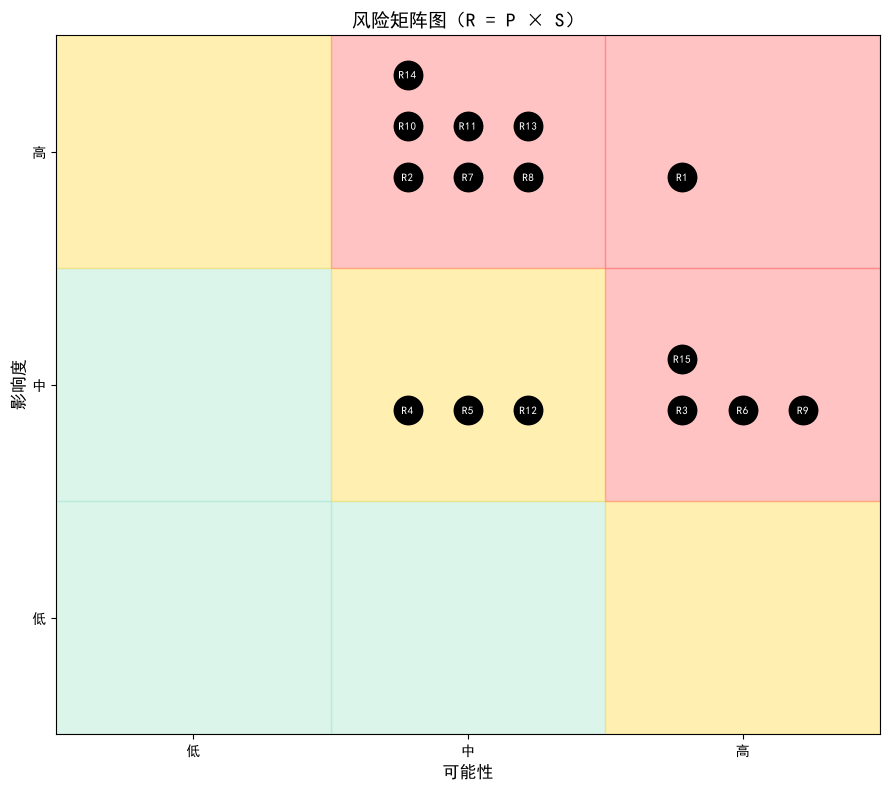

已保存： ..\results\charts\risk_matrix.png


In [1]:
# 风险矩阵图（R = P × S）
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict
from pathlib import Path

matplotlib.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
matplotlib.rcParams['axes.unicode_minus'] = False

risks = {
    "R1": (3, 3), "R2": (2, 3), "R3": (3, 2), "R4": (2, 2),
    "R5": (2, 2), "R6": (3, 2), "R7": (2, 3), "R8": (2, 3),
    "R9": (3, 2), "R10": (2, 3), "R11": (2, 3), "R12": (2, 2),
    "R13": (2, 3), "R14": (2, 3), "R15": (3, 2),
}

fig, ax = plt.subplots(figsize=(9, 8))

# 背景色
for i in range(3):
    for j in range(3):
        p, s = i + 1, j + 1
        r = p * s
        color = "#ff6b6b" if r >= 6 else ("#ffd93d" if r >= 3 else "#a8e6cf")
        ax.add_patch(plt.Rectangle((i, j), 1, 1, color=color, alpha=0.4))

# 同一格子内的点错开
grouped = defaultdict(list)
for rid, (p, s) in risks.items():
    grouped[(p, s)].append(rid)

for (p, s), ids in grouped.items():
    n = len(ids)
    for k, rid in enumerate(ids):
        # 在 0.6x0.6 的小范围内散开
        offset_x = (k % 3 - 1) * 0.22
        offset_y = (k // 3 - 0.5) * 0.22
        x = (p - 0.5) + offset_x
        y = (s - 0.5) + offset_y

        ax.scatter(x, y, s=420, color="black", zorder=3)
        ax.text(x, y, rid, ha="center", va="center",
                fontsize=8, color="white", fontweight="bold", zorder=4)

ax.set_xticks([0.5, 1.5, 2.5])
ax.set_xticklabels(["低", "中", "高"])
ax.set_yticks([0.5, 1.5, 2.5])
ax.set_yticklabels(["低", "中", "高"])
ax.set_xlim(0, 3)
ax.set_ylim(0, 3)
ax.set_xlabel("可能性", fontsize=12)
ax.set_ylabel("影响度", fontsize=12)
ax.set_title("风险矩阵图（R = P × S）", fontsize=14)

CHART_DIR = Path("../results/charts")
CHART_DIR.mkdir(parents=True, exist_ok=True)
plt.tight_layout()
plt.savefig(CHART_DIR / "risk_matrix.png", dpi=200, bbox_inches="tight")
plt.show()
print("已保存：", CHART_DIR / "risk_matrix.png")